<a href="https://colab.research.google.com/github/maramgueye/datascience_with_python/blob/main/Final_Assessment_Gueye_Maram_studentID.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Fundamentals of statistics and data science with Python: Final assessment**

## Introduction

This notebook is my submission for the final assessment of the course 'Fundamentals of statistics and data science with Python'.

The assignment has five parts and uses two datasets

Firstly, let's make the relevant import

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

#**1. Python exercise: Perfect numbers**


Definition: A perfect number is a positive integer that is equal to the sum of its proper divisors (excluding the
number itself). For example:

• 6 is a perfect number because its divisors (excluding 6) are 1, 2, and 3, and 1 + 2 + 3 = 6.

• 28 is a perfect number because its divisors (excluding 28) are 1, 2, 4, 7, and 14, and 1 + 2 + 4 + 7 + 14 = 28.

1. Write a Python function is_perfect_number(n) that checks whether a given integer n is a perfect number.
The function should return True if n is a perfect number and False otherwise.

In [2]:
def is_perfect_number(n):
    '''
    Test if n is a perfect number.
    return True if n is a perfect number and False otherwise

    '''
    #we will firstly take the divisor of the number n excluding n itselves
    div=[]
    for i in range (1, n):
        if n%i==0:
            div.append(i)
    #then we are going to do the sum of the divisor and verify if the result is equal to our number n
    div=np.array(div)
    if div.sum()==n:
        return True
    else:
        return False

Let's run tests with the example given and other non perfect number

In [3]:
#test
test_lst=[6, 7, 12,28]
for n in test_lst:
    if is_perfect_number(n):
        print (f'{n} is a perfect number')
    else :
        print(f'{n} is not a perfect number')

6 is a perfect number
7 is not a perfect number
12 is not a perfect number
28 is a perfect number


#**2. Describe and summarize the dataset**

### 1. Load the data_invoices.xlsx dataset and compute the following descriptive statistics for all continuous variables:
   
(a) Mean

(b) Median

(c) Variance

(d) Standard deviation

(e) Minimum and maximum values

(f) First and third quartiles

La cellule suivant est a execute uniquement si le fichier est lu sur google collab, sinon passe au cellule suivant

In [4]:
from google.colab import files

uploaded = files.upload()

Saving data_invoices.xlsx to data_invoices.xlsx


In [5]:
data=pd.read_excel('data_invoices.xlsx', sheet_name='data_invoices')

data.head(7)

,id_invoice,amount,age customer,items bought,debit card
0,1,163.5,43,7,0
1,2,138.8,39,5,0
2,3,175.9,48,7,1
3,4,157.5,45,11,1
4,5,600.0,43,2,0
5,6,132.8,32,5,0
6,7,165.7,42,3,1


In [6]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   id_invoice    2000 non-null   int64  
 1   amount        2000 non-null   float64
 2   age customer  2000 non-null   int64  
 3   items bought  2000 non-null   int64  
 4   debit card    2000 non-null   int64  
dtypes: float64(1), int64(4)
memory usage: 78.3 KB


In [7]:
data.isnull().sum()

,0
id_invoice,0
amount,0
age customer,0
items bought,0
debit card,0


In [8]:
data.shape

(2000, 5)

We can see that their is no missing values in our dataset

In [9]:
data.describe(include='all')


,id_invoice,amount,age customer,items bought,debit card
count,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000
mean,1000.500000,154.153150,40.072000,8.513500,0.702500
std,577.494589,30.487148,5.052483,4.743635,0.457273
min,1.000000,20.000000,24.000000,0.000000,0.000000
25%,500.750000,134.975000,37.000000,5.000000,0.000000
50%,1000.500000,154.750000,40.000000,8.000000,1.000000
75%,1500.250000,172.525000,43.000000,12.000000,1.000000
max,2000.000000,600.000000,58.000000,32.000000,1.000000


We can notice that they are some descriptions missings, let's add them

In [10]:
print(f'      The variances are: \n{data.var()}\n')
print(f'      The medians are: \n{data.median()}')

      The variances are: 
id_invoice      333500.000000
amount             929.466183
age customer        25.527580
items bought        22.502069
debit card           0.209098
dtype: float64

      The medians are: 
id_invoice      1000.50
amount           154.75
age customer      40.00
items bought       8.00
debit card         1.00
dtype: float64


### 2. For the categorical variables, count the occurrences of each unique value.
It is only the column debit card that hav categorical variables with 0 representing 'No' and 1 representing 'Yes'

In [11]:
counts = data['debit card'].value_counts()
counts

,count
debit card,
1,1405
0,595


In [12]:
# let's take the percentage of the occurence each of the categorical variables
counts = data['debit card'].value_counts(normalize=True)*100
counts

,proportion
debit card,
1,70.25
0,29.75


Out of 2,000 invoices, we can see that there is a majority of payment by debit card with a percentage of 70.25% and only 29.75% that did not pay by card. Debit cards are therefore the dominant payment method in this dataset.

### 3. Choose the most appropriate visuals to display the distribution of each continuous variable. Justify your choice.

We are now going to plot 'Amount', 'age customer' and 'items_bought' with a histogram because it is the standard way to show the shap of a distribution for continuous variables.

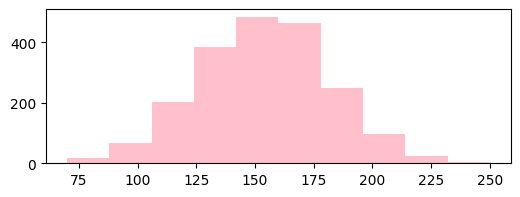

In [13]:
plt.figure(figsize=(6,2))
plt.hist(data['amount'], range=(70, 250),color='pink')
# I choosed a range of (70,250) to better see the shape of the histograms but..
# from exercice 2, we know that amount min is 20 and its max is 600
plt.show()

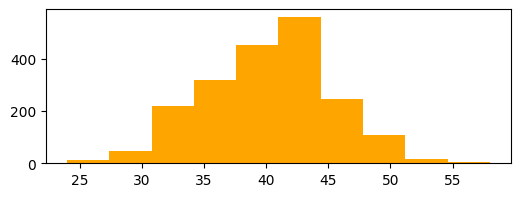

In [14]:
plt.figure(figsize=(6,2))
plt.hist(data['age customer'], color='orange')
plt.show()

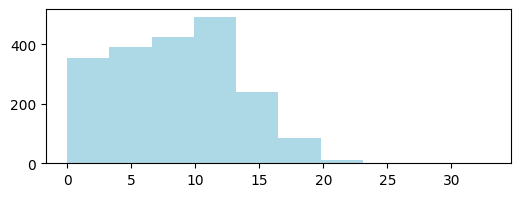

In [15]:
plt.figure(figsize=(6,2))
plt.hist(data['items bought'], range = (0, 33), color='lightblue')
plt.show()

### We have 3 plots, we can put them in the same subplot to see all three of them at the same tiem

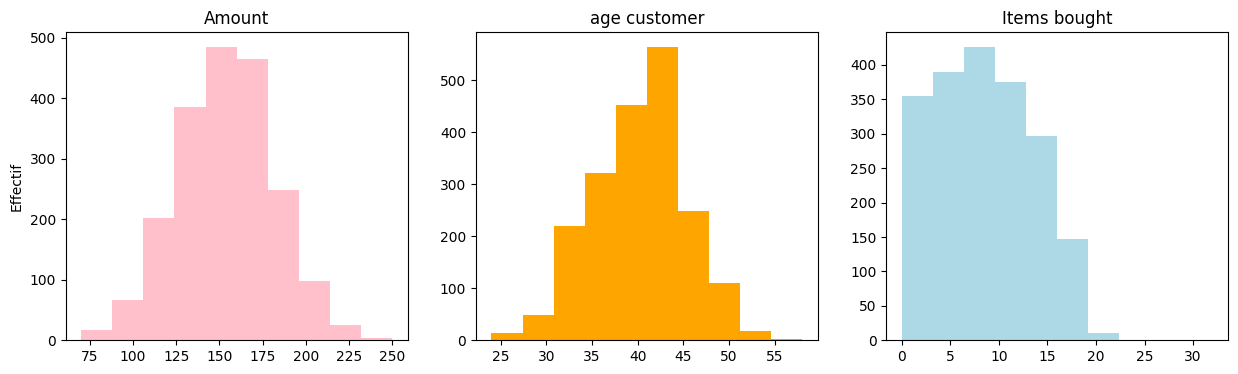

In [16]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
# amount
ax[0].hist(data['amount'], range=(70, 250), color='pink')
ax[0].set_title('Amount')
ax[0].set_ylabel('Effectif')
# age customer
ax[1].hist(data['age customer'], color='orange')
ax[1].set_title('age customer')
# items bought
ax[2].hist(data['items bought'], color='lightblue')
ax[2].set_title('Items bought')

#plt.tight_layout()
plt.show()

### 4. Choose the most appropriate visuals to display the frequency of each value for categorical variables. Justify your choice.

A bar chart is the most appropriate visual for a categorical variable like the one for the usage of debit card. Each bar shows the number of invoices in one category, and the bars are compared from the same zero baseline, so the heights are easy to read.

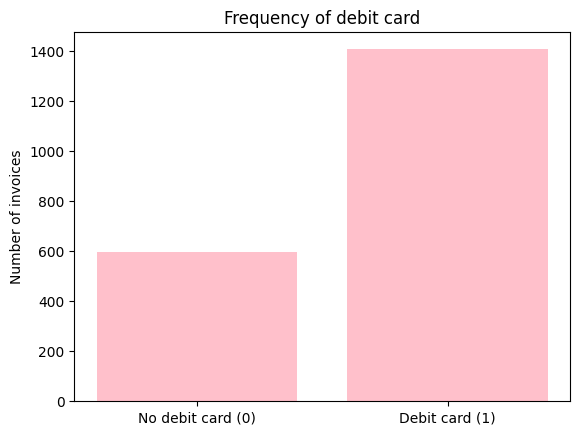

In [17]:
counts = data['debit card'].value_counts()
names = counts.index
val=counts.values
plt.bar(counts.index, counts.values, color='pink')
# so that we only have 0 and 1 on the x-axis, and not '0,2', 0,4' chich is inconsistent with our dataset
plt.xticks(names, ['Debit card (1)','No debit card (0)'])
plt.ylabel('Number of invoices')
plt.title('Frequency of debit card')
plt.show()

### 5. Compute the correlation between the column amount and age customer, as well as between amount and items bought.

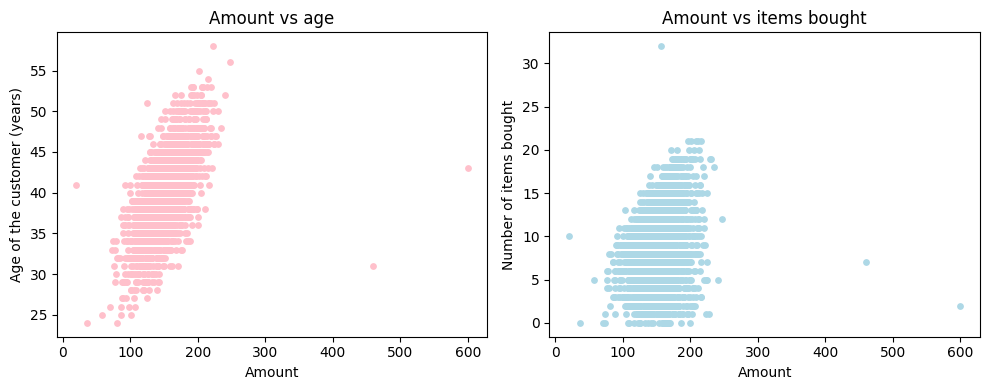

In [18]:
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.scatter(data['amount'], data['age customer'],
            color='pink', s=15)
plt.xlabel('Amount')
plt.ylabel('Age of the customer (years)')
plt.title('Amount vs age')
plt.subplot(1, 2, 2)
plt.scatter(data['amount'], data['items bought'],
            color='lightblue', s=15)
plt.xlabel('Amount')
plt.ylabel('Number of items bought')
plt.title('Amount vs items bought')

plt.tight_layout()
plt.show()

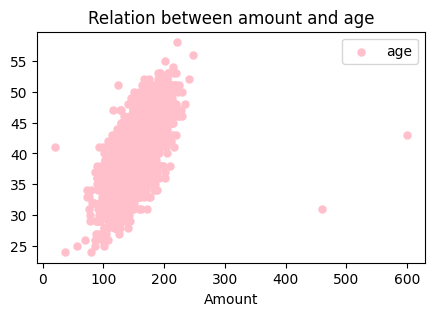

In [19]:
plt.figure(figsize=(5,3))
plt.scatter(data['amount'], data['age customer'], color='pink', label= 'age', linewidths=0.05)
plt.legend()
plt.xlabel('Amount')
plt.title("Relation between amount and age")
plt.show()

In [20]:
data[['amount', 'age customer']].corr()

,amount,age customer
amount,1.000000,0.615239
age customer,0.615239,1.000000


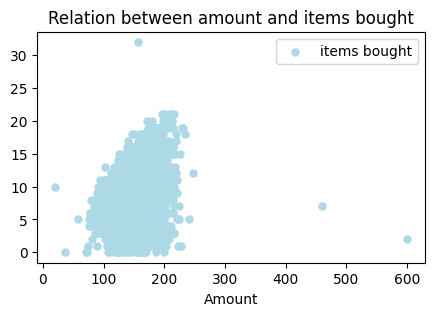

In [21]:
plt.figure(figsize=(5,3))
plt.scatter(data['amount'], data['items bought'], color='lightblue', label= 'items bought', linewidths=0.05)
plt.legend()
plt.xlabel('Amount')
plt.title("Relation between amount and items bought")
plt.show()

In [22]:
data[['amount', 'items bought']].corr()

,amount,items bought
amount,1.000000,0.234581
items bought,0.234581,1.000000


### 6. Interpret the correlation results.

- Amount and age (0.615): have a positive linear relationship. Older customers tend to have larger invoices, and age alone explains about 38% of the variance of the amount.

- Amount and items bought (0.235): have a weak positive relationship. More items tend to go with a slightly higher amount, but the number of items is a poor predictor on its own.

**Correlation does not imply causation**. The few extreme amounts (460 and 600) can distort a Pearson coefficient.

### 7. Choose the most appropriate visualization to summarize the distribution of the amounts paid by clients who used a debit card and those who did not. Justify your choice

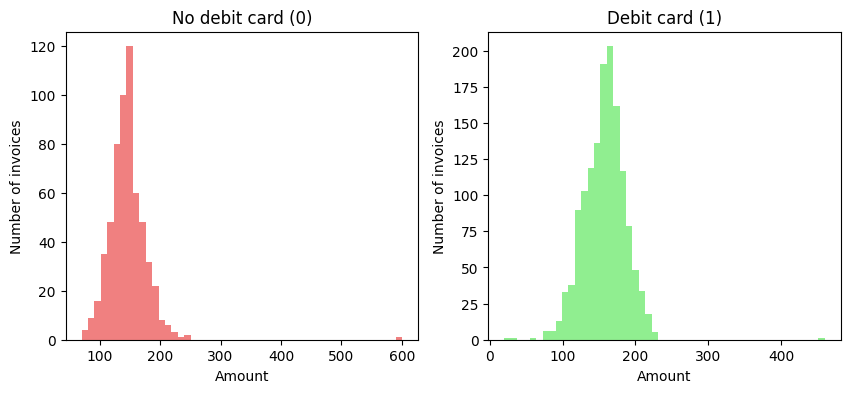

In [23]:
debit = data.loc[data['debit card'] == 1, 'amount']
no_debit = data.loc[data['debit card'] == 0, 'amount']

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.hist(no_debit, 50, color='lightcoral')
plt.xlabel('Amount')
plt.ylabel('Number of invoices')
plt.title('No debit card (0)') #no debit
#plt.legend()

plt.subplot(1, 2, 2)
plt.hist(debit, 50, color='lightgreen')
plt.xlabel('Amount')
plt.ylabel('Number of invoices') #with debit
plt.title('Debit card (1)')
#plt.legend()
plt.show()

#**3. Linear Regression**


### 1. Build a linear regression model where the dependent variable is amount, and the independent variables are age customer, items bought and credit card.

### (a) Report the coefficients and intercept of the model.



In [24]:
data.head(10)

,id_invoice,amount,age customer,items bought,debit card
0,1,163.5,43,7,0
1,2,138.8,39,5,0
2,3,175.9,48,7,1
3,4,157.5,45,11,1
4,5,600.0,43,2,0
5,6,132.8,32,5,0
6,7,165.7,42,3,1
7,8,134.1,39,2,1
8,9,174.0,39,1,1
9,10,183.7,41,11,1


In [25]:
from sklearn.linear_model import LinearRegression
X = data[['age customer', 'items bought', 'debit card']].values
Y = data[['amount']].values
multi_model = LinearRegression().fit(X, Y)
coefficients=multi_model.coef_
intercept = multi_model.intercept_

print(f'coefficient de "age customer": {coefficients[0][0]}')
print(f'coefficient de "items bought": {coefficients[0][1]}')
print(f'coefficient de "debit card": {coefficients[0][2]}')
#print(coefficients)
print(f'intercept :{intercept}')

coefficient de "age customer": 3.5046160428827413
coefficient de "items bought": 0.7634451378304434
coefficient de "debit card": 6.074812501877325
intercept :[2.94902997]


0.40042722528249064


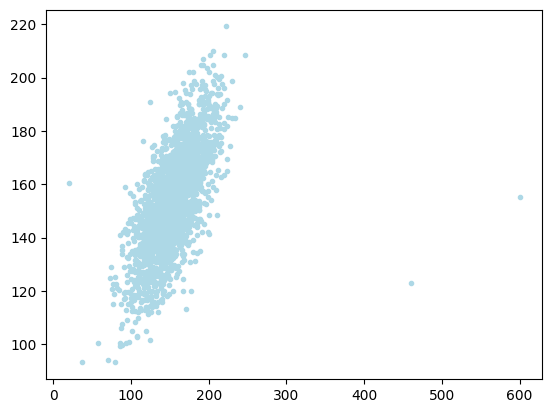

In [26]:
Y_pred =multi_model.predict(X)
plt.plot(Y, Y_pred, '.', color='lightblue')
print(multi_model.score(X, Y))

### (b) Interpret the meaning of each coefficient.



- Intercept (2.95)
The intercept is the predicted amount when all the independent variables are equal to 0. This case does not exist in the data (the customers are between 24 and 58 years old), so the intercept has no real-world meaning. It is only the starting point of the regression line.

- age customer (3.50)
Each additional year of age is associated with an invoice that is 3.50 monetary units higher, on average. For example, if we compare two customers who bought the same number of items and paid in the same way, but one is 10 years older, the older customer's invoice is expected to be about 35 units higher (10 x 3.50).
This is the largest effect in the model, which is consistent with the correlation of 0.62 between age and amount.

- items bought (0.76)
Each additional item in the basket is associated with an invoice that is 0.76 monetary units higher, on average, for customers of the same age and the same payment method. Buying 5 more items corresponds to an invoice only about 3.8 units higher (5 x 0.76).
The effect per item is small, which is consistent with the weak correlation of 0.23 between items bought and amount.

- debit card (6.07)
For two customers of the same age who bought the same number of items, the one who paid with a debit card is expected to have an invoice 6.07 units higher than the one who did not. This difference of 6.07 is smaller than the raw gap between the group means (about 11), because debit card users are also slightly older and buy slightly more items: the model removes the part of the gap that comes from age and number of items.



### (c) Compute and report the R-squared statistic and explain what it tells you about the model’s fit

In class we used two ways to compute the r-squared, I am going to use both so as to show that they are equivalent

In [27]:
print('R2_dot:', multi_model.score(X, Y))
from sklearn.metrics import r2_score
Y_pred = multi_model.predict(X)
print('R2_skmetrics :', r2_score(Y, Y_pred))

R2_dot: 0.40042722528249064
R2_skmetrics : 0.40042722528249064


R-squared is equal to around 0.40 so that means that the 3 predictors together explain about 40% of the variance of the invoice amount.
So we have a remaining 60% that are likely due factors that are not in the model (or just to pure randomness).
This is a moderate fit so as to say that the model captures a real pattern but is far from precise. Also as we saw in previous exercice, age alone
already explains about 38%, so 'items_bought' and 'debit_card' add only about two percentage points.

We can also add that the adjusted R² (0.3995) is virtually
identical to R² (0.4004), which shows that the model is not overfitted by its
three predictors.

### 2. Use the model to calculate the Root Mean Square Error (RMSE).
Definition: The Root Mean Square Error (RMSE) measures the average magnitude of the error between the predicted values and the observed values.

In [34]:
from sklearn.metrics import root_mean_squared_error
Y_pred = multi_model.predict(X)
rmse=root_mean_squared_error(Y, Y_pred)
print('RMSE :',rmse )

RMSE : 23.60093170066717


In [38]:
print('RMSE :', rmse)
print(f'mean of amount :{data['amount'].mean()}')
print(f'std of amount  :{data['amount'].std()}')
print(f'RMSE / mean    :{rmse / data['amount'].mean()}')
print(f'RMSE / std     :{rmse / data['amount'].std()}')

RMSE : 23.60093170066717
mean of amount :154.15315
std of amount  :30.48714783591743
RMSE / mean    :0.15310054773883744
RMSE / std     :0.7741272429840915



3. Interpret the RMSE value and what it indicates about the model’s performance.


The RMSE is around 23.6. So that is the typical size of the error of the model. Which means that, on average, the predicted amount differs from the real invoice amount by about 23.6 units.

To judge if this is large or small, I compare it with the amount itself:
- it is about 15% of the mean amount (154.15);
- it is only about 23% lower than the standard deviation of the amount (30.5), which is the error we would make by always predicting the mean.

So the model does better than a naive prediction, but not by a lot. This is consistent with an R-squared of 0.40.
The RMSE also gives more weight to large errors, and the plot of observed against predicted values shows a few extreme invoices (such as 600 and 460) that are badly predicted. Finally, the RMSE is computed on the same data used to fit the model, so it is probably a bit optimistic for new data.

#**4. Inference and hypothesis testing**



### 1. Compute 95% confidence intervals for the sample means of age customer and amount.

In [30]:
from scipy import stats
ci_95=stats.norm.interval(0.95)
np.abs(ci_95)

array([1.95996398, 1.95996398])

In [31]:
age_mean=np.mean(data['age customer'])
amount_mean=np.mean(data['amount'])
print(f'age mean is {age_mean}')
print(f'amount mean is {amount_mean}')

age mean is 40.072
amount mean is 154.15315


### **For customer age**

In [32]:
N_age = len(data['age customer'])
se_age = data['age customer'].std() / np.sqrt(N_age)
print(f"age : for a 95% confidence intervals we have [{age_mean - ci_95[1]*se_age} ; {age_mean + ci_95[1]*se_age}]")

age : for a 95% confidence intervals we have [39.8505692585086 ; 40.293430741491406]


### **For amount**

In [33]:
N_amount = len(data['amount'])
se_amount = data['amount'].std() / np.sqrt(N_amount)
print(f"amount : for a 95% confidence intervals we have[{amount_mean - ci_95[1]*se_amount} ; {amount_mean + ci_95[1]*se_amount}]")

amount : for a 95% confidence intervals we have[152.8170163861964 ; 155.48928361380362]


### **interpretation**
- We are 95% confident that the mean customer age in the population is
between between 39.85 and 40.29 years.
- We are also 95% confident that the mean invoice amount
is between about 152.82 and 155.49.


## 2. Evaluate the claim: “People who used a debit card paid higher amounts.”. Describe the hypothesis test you would perform to assess this claim and explain the logic behind your chosen method

#**5 .Time series analysis**

1. Load the MSFT.csv dataset and create time series plots for the columns Close and Volume.


In [40]:
from google.colab import files
uploaded = files.upload()

Saving MSFT.csv to MSFT.csv


In [42]:
datamsft=pd.read_csv('MSFT.csv')
datamsft.head(5)

,Date,Open,High,Low,Close,Volume
0,19/07/2023,361.750000,362.459991,352.440002,355.079987,39732900
1,20/07/2023,353.570007,357.970001,345.369995,346.869995,33778400
2,21/07/2023,349.149994,350.299988,339.829987,343.769989,69368900
3,24/07/2023,345.850006,346.920013,342.309998,345.109985,26678100
4,25/07/2023,347.109985,351.890015,345.070007,350.980011,41637700


In [43]:
# The dates are written day/month/year, so we give the format explicitly
datamsft['Date'] = pd.to_datetime(datamsft['Date'], format='%d/%m/%Y')
datamsft.set_index('Date', inplace=True)
datamsft.sort_index(inplace=True)   # so as to make sure the dates are in chronological order

datamsft.info()
datamsft.head()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 253 entries, 2023-07-19 to 2024-07-19
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Open    253 non-null    float64
 1   High    253 non-null    float64
 2   Low     253 non-null    float64
 3   Close   253 non-null    float64
 4   Volume  253 non-null    int64  
dtypes: float64(4), int64(1)
memory usage: 11.9 KB


,Open,High,Low,Close,Volume
Date,,,,,
2023-07-19,361.750000,362.459991,352.440002,355.079987,39732900
2023-07-20,353.570007,357.970001,345.369995,346.869995,33778400
2023-07-21,349.149994,350.299988,339.829987,343.769989,69368900
2023-07-24,345.850006,346.920013,342.309998,345.109985,26678100
2023-07-25,347.109985,351.890015,345.070007,350.980011,41637700


In [44]:
datamsft['Close_05'] = datamsft['Close'].rolling(window=5).mean()
datamsft['Close_10'] = datamsft['Close'].rolling(window=10).mean()

datamsft['Volume_05'] = datamsft['Volume'].rolling(window=5).mean()
datamsft['Volume_10'] = datamsft['Volume'].rolling(window=10).mean()

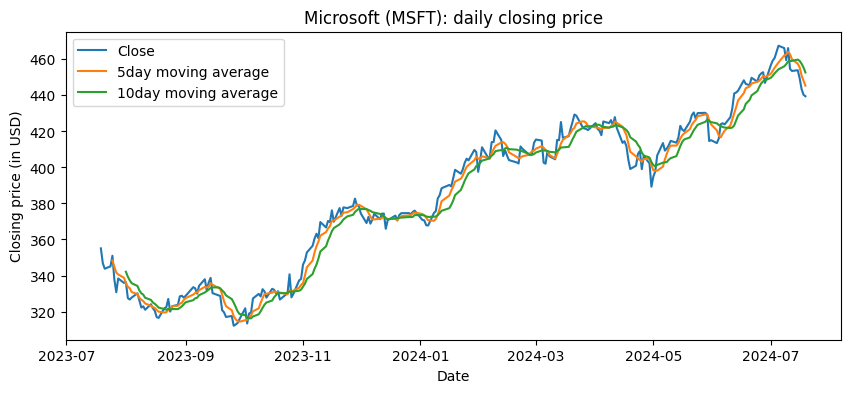

In [45]:
plt.figure(figsize=(10, 4))
plt.plot(datamsft['Close'], label='Close')
plt.plot(datamsft['Close_05'], label='5day moving average')
plt.plot(datamsft['Close_10'], label='10day moving average')
plt.xlabel('Date')
plt.ylabel('Closing price (in USD)')
plt.title('Microsoft (MSFT): daily closing price')
plt.legend()
plt.show()

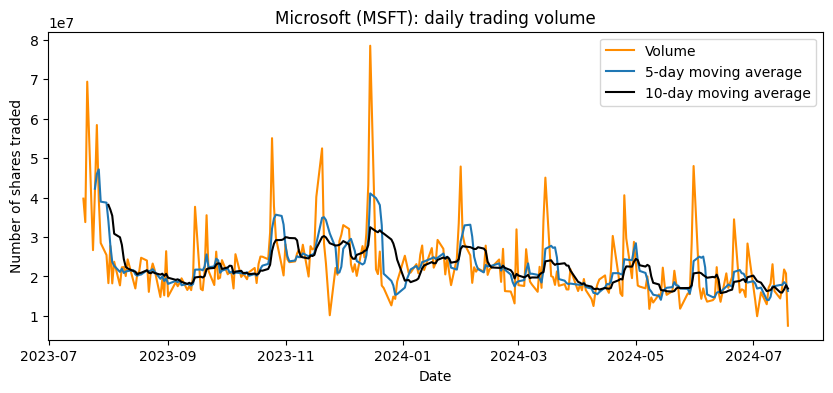

In [46]:
plt.figure(figsize=(10, 4))
plt.plot(datamsft['Volume'], color='darkorange', label='Volume')
plt.plot(datamsft['Volume_05'], label='5-day moving average')
plt.plot(datamsft['Volume_10'], color='black', label='10-day moving average')
plt.xlabel('Date')
plt.ylabel('Number of shares traded')
plt.title('Microsoft (MSFT): daily trading volume')
plt.legend()
plt.show()

### 2. Analyze and describe any seasonality and trend observed in both time series.


I used period=5 because the data is daily (trading days only), so one cycle is a trading week.

###**- for Close**

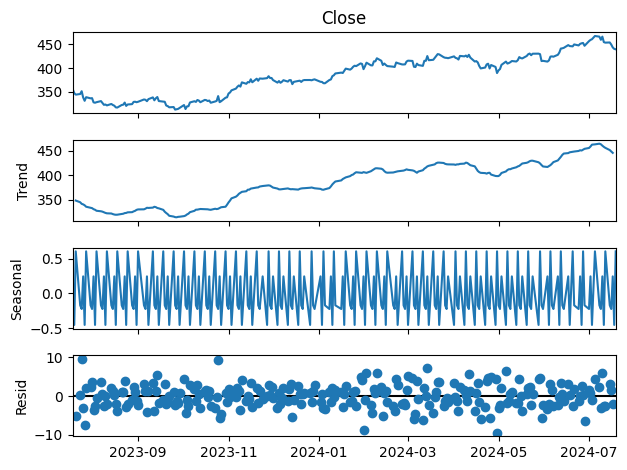

In [47]:
from statsmodels.tsa.seasonal import seasonal_decompose
result_close = seasonal_decompose(datamsft['Close'], model='additive', period=5)
result_close.plot()
plt.show()

### **-for Volume**

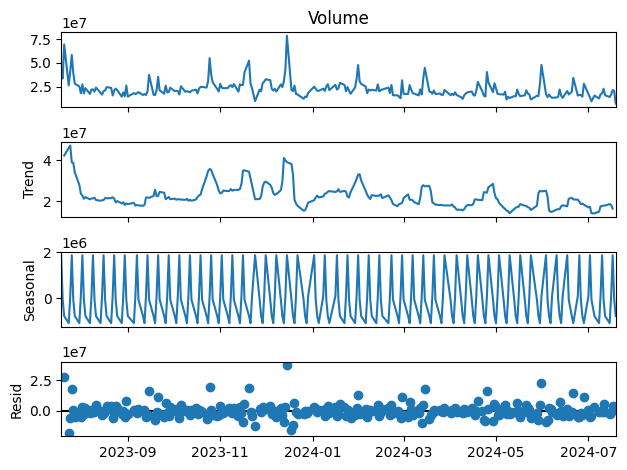

In [48]:
result_volume = seasonal_decompose(datamsft['Volume'], model='additive', period=5)
result_volume.plot()
plt.show()

- The types of Series looks additive, as the amplitude of the fluctuations stays roughly constant (about 4 to 5 USD from one day to the next for 'Close') while the level changes only moderately.

### Trend.
- **Close**: upward trend. From about 355 (19/07/2023) to about 440 (19/07/2024), roughly +24%. It is not a straight line: a drift down to a low of 312.1 (26/09/2023), a strong rise until December 2023, a pause, a rise until March 2024, a correction in April, then a climb to a peak of 467.6 on 05/07/2024. The trend component of the decomposition goes from about 348 to about 445.
- **Volume**: we can notice a downward trend. After a very active start, volume is highest in November–December 2023 (about 26 million shares a day) and then falls steadily to about 16 million in July 2024.
### Seasonality
- No annual seasonality can be assessed with only one year of data (at least two full cycles are needed), and the plots show no regular repeating cycle. With a weekly period, the seasonal component of 'Close' varies by only about 1 USD (against a price range of about 155), and that of 'Volume' by about 3 million shares (against a range of about 71 million). The weekly pattern is therefore negligible.
### Conclusion
Both series are dominated by their trend plus some irregular fluctuations, with no clear seasonality.

### 3. Compute the correlation between Close and Volume. Interpret the result. Does the result align with what you observe in the plots ?


In [49]:
datamsft[['Close', 'Volume']].corr()

,Close,Volume
Close,1.000000,-0.245042
Volume,-0.245042,1.000000


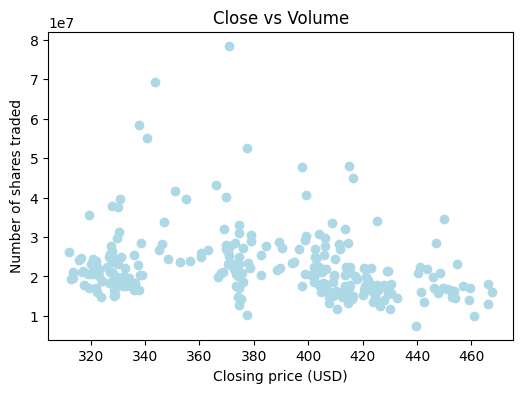

In [50]:
plt.figure(figsize=(6, 4))
plt.scatter(datamsft['Close'], datamsft['Volume'],color='lightblue')
plt.xlabel('Closing price (USD)')
plt.ylabel('Number of shares traded')
plt.title('Close vs Volume')
plt.show()

The correlation between Close and Volume is about -0.245: a small negative correlation. On days when the price is higher, the volume tends to be lower. The price explains only about 6% of the variance of the volume.

It aligns with the plots. Close has an upward trend while Volume has a downward trend, so the two series move in opposite directions over the year. In the scatter plot, the high-volume points are mostly at low prices (the beginning of the period).



### Pour aller plus loin
In our current portfolio construction theory class, we saw the function 'pct_change()'

In [51]:
# Correlation of the daily % changes (the trends are removed)
datamsft[['Close', 'Volume']].pct_change().corr()

,Close,Volume
Close,1.000000,-0.102017
Volume,-0.102017,1.000000


Caution : This correlation mainly comes from the two opposite trends, not from a day-to-day link. When the trends are removed by correlating the daily percentage changes, the correlation is about -0.10, close to zero. We cannot conclude that a rising price makes the volume fall.

### 4. Do you observe any outliers in the two time series ? Are there any points where the trajectory of the time series shows a noticeable shift or change ?
**Definition: An outlier is an extreme value that deviates significantly from other observations in a dataset. It is
an observation that lies an abnormal distance from other values.**

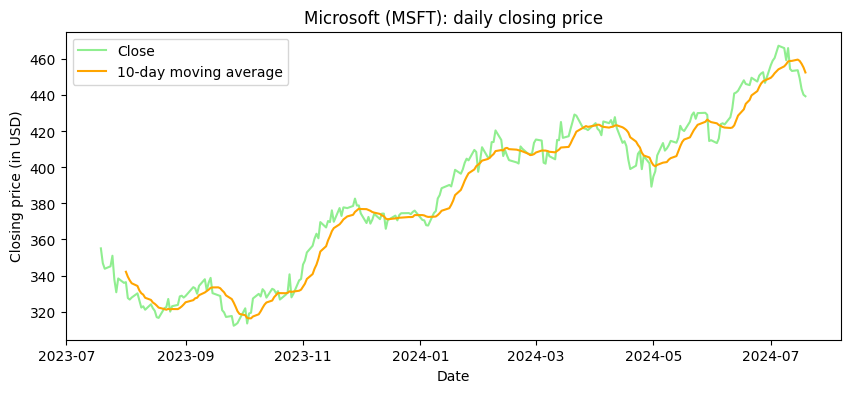

In [66]:
plt.figure(figsize=(10, 4))
plt.plot(datamsft['Close'], label='Close', color='lightgreen')
plt.plot(datamsft['Close_10'], label='10-day moving average',color='orange')
plt.xlabel('Date')
plt.ylabel('Closing price (in USD)')
plt.title('Microsoft (MSFT): daily closing price')
plt.legend()
plt.show()

In [62]:
# we want to have the 5 bigger values and their dates
top5 = datamsft['Volume'].sort_values(ascending=False).head(5)
print(top5)

Date
2023-12-15    78478200
2023-07-21    69368900
2023-07-26    58383700
2023-10-25    55053800
2023-11-20    52465100
Name: Volume, dtype: int64


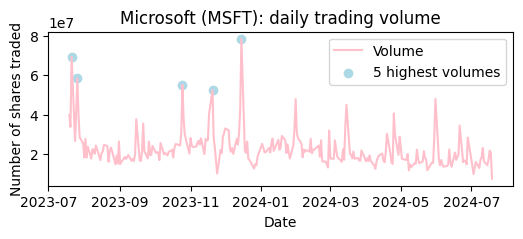

In [61]:
plt.figure(figsize=(6, 2))
plt.plot(datamsft['Volume'], color='pink', label='Volume')
plt.scatter(top5.index, top5, color='lightblue', label='5 highest volumes')
plt.xlabel('Date')
plt.ylabel('Number of shares traded')
plt.title('Microsoft (MSFT): daily trading volume')
plt.legend()
plt.show()